In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report)

In [39]:
df=pd.read_csv("Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")

In [40]:
#first 5 datapoints
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [41]:
#shape,columns, of the Dataset
print("Shape: ",df.shape)
print("\n")
print("All Columns: \n",df.columns)

Shape:  (225745, 79)


All Columns: 
 Index([' Destination Port', ' Flow Duration', ' Total Fwd Packets',
       ' Total Backward Packets', 'Total Length of Fwd Packets',
       ' Total Length of Bwd Packets', ' Fwd Packet Length Max',
       ' Fwd Packet Length Min', ' Fwd Packet Length Mean',
       ' Fwd Packet Length Std', 'Bwd Packet Length Max',
       ' Bwd Packet Length Min', ' Bwd Packet Length Mean',
       ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s',
       ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min',
       'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max',
       ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std',
       ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags',
       ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length',
       ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s',
       ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean',
       ' Packet Len

In [42]:
#Leading and Trailing removal
df.columns=df.columns.str.strip()

In [43]:
# Check non-numeric columns in the dataset
categorical_cols = df.select_dtypes(include=['object']).columns
print("Non-numeric columns in dataset:", list(categorical_cols))

Non-numeric columns in dataset: ['Label']


In [44]:
#check datatype
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             225745 non-null  int64  
 1   Flow Duration                225745 non-null  int64  
 2   Total Fwd Packets            225745 non-null  int64  
 3   Total Backward Packets       225745 non-null  int64  
 4   Total Length of Fwd Packets  225745 non-null  int64  
 5   Total Length of Bwd Packets  225745 non-null  int64  
 6   Fwd Packet Length Max        225745 non-null  int64  
 7   Fwd Packet Length Min        225745 non-null  int64  
 8   Fwd Packet Length Mean       225745 non-null  float64
 9   Fwd Packet Length Std        225745 non-null  float64
 10  Bwd Packet Length Max        225745 non-null  int64  
 11  Bwd Packet Length Min        225745 non-null  int64  
 12  Bwd Packet Length Mean       225745 non-null  float64
 13 

In [45]:
print(df['Label'].value_counts())

Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64


In [46]:
#missing value count
print(df.isnull().sum()[df.isnull().sum()>0])

Flow Bytes/s    4
dtype: int64


In [47]:
#Drop Null Values
df.dropna(inplace=True)

In [48]:
#Drop Duplicate Values
print("Duplicates count:", df.duplicated().sum())
df.drop_duplicates(inplace=True)


Duplicates count: 2633


In [49]:
#check constant columns and drop them
const=[col for col in df.columns if df[col].nunique() <=1]
print("Constant Columns:\n",const)
print("total constant columns:\n",len(const))


Constant Columns:
 ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
total constant columns:
 10


In [50]:
df.drop(columns=const,inplace=True)


In [51]:

df = df[(df['Total Fwd Packets'] > 0) | (df['Total Backward Packets'] > 0)]
df = df[df['Flow Bytes/s'] > 0]


In [52]:
df.replace([np.inf, -np.inf], np.nan,inplace=True)
df.dropna(inplace=True)

In [53]:
print("Remaining Shape",df.shape)

Remaining Shape (218219, 69)


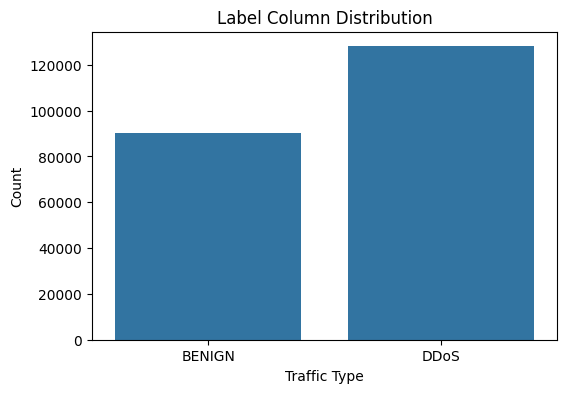

In [54]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Label', data=df)
plt.title("Label Column Distribution")
plt.xlabel("Traffic Type")
plt.ylabel("Count")
plt.show()

In [55]:
# Change DDos 0 and BENIGN 1
df['Label'] = df['Label'].map({'BENIGN': 0, 'DDoS': 1})

In [56]:

print(df.groupby('Label')['Destination Port'].value_counts().sample(10))

Label  Destination Port
0      28910               1
       9681                3
       24985               1
       55048               2
       40470               1
       54382               2
       29788               1
       56632               4
       17202               1
       60712               2
Name: count, dtype: int64


In [57]:
df['Label'].sample(10)
print(df['Label'].value_counts())

Label
1    128014
0     90205
Name: count, dtype: int64


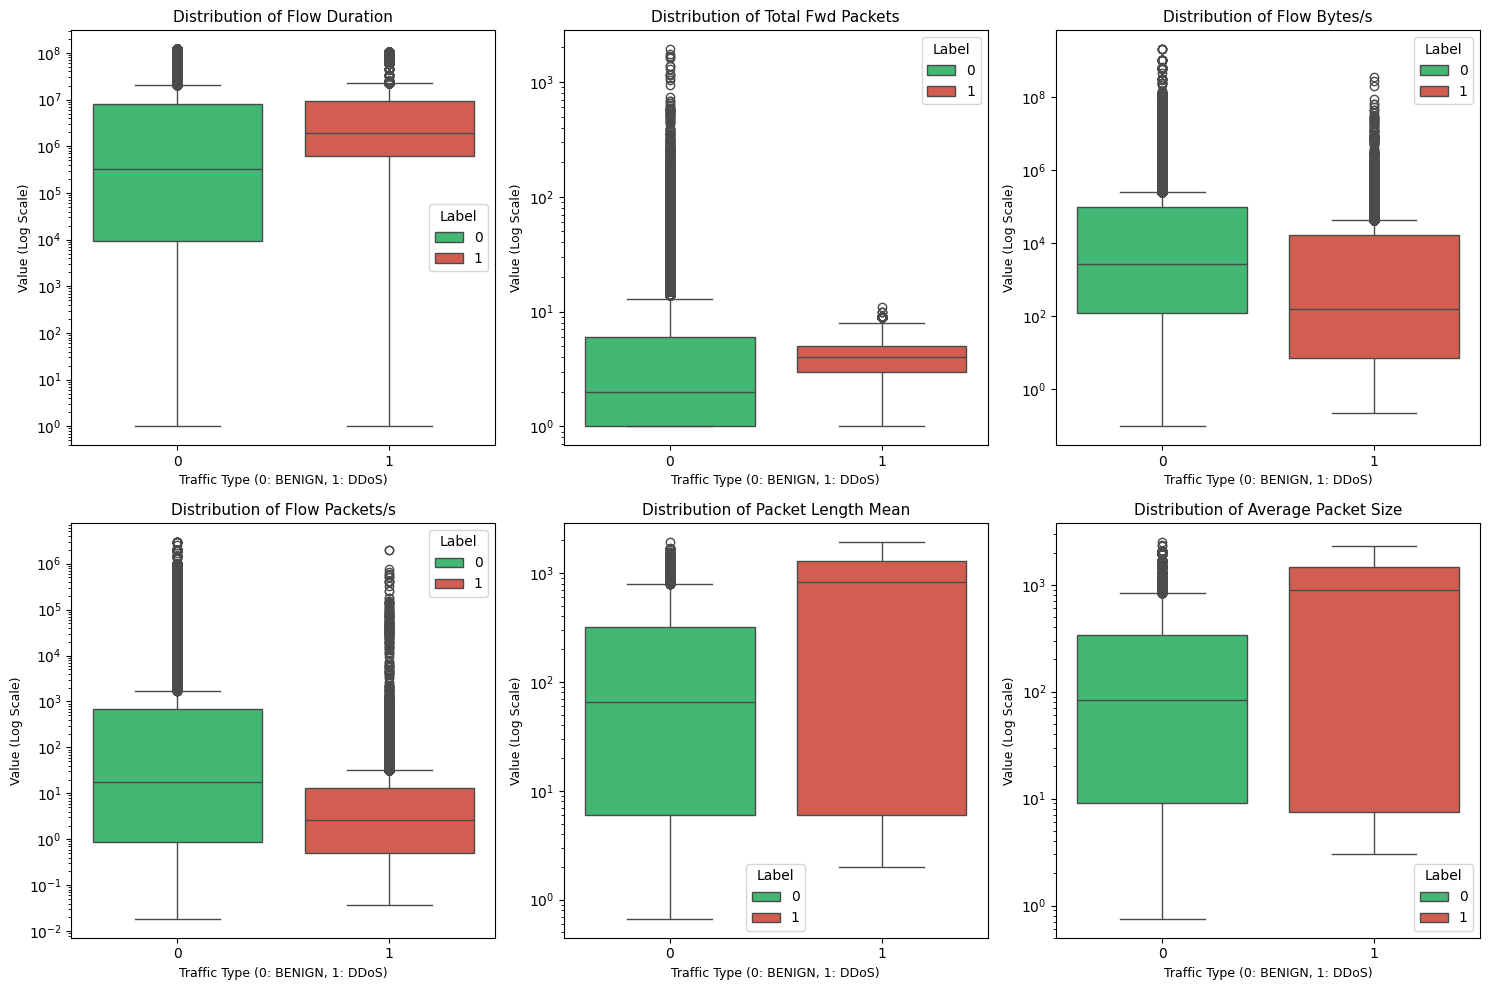

In [58]:
key_features = [
    'Flow Duration',
    'Total Fwd Packets',
    'Flow Bytes/s',
    'Flow Packets/s',
    'Packet Length Mean',
    'Average Packet Size'
]
plt.figure(figsize=(15, 10))
for i, col in enumerate(key_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='Label', y=col,hue='Label', data=df, palette=['#2ecc71', '#e74c3c'])
    plt.yscale('log')
    plt.title(f'Distribution of {col}', fontsize=11)
    plt.xlabel('Traffic Type (0: BENIGN, 1: DDoS)', fontsize=9)
    plt.ylabel('Value (Log Scale)', fontsize=9)

plt.tight_layout()
plt.show()


In [59]:

spearman_corr = df.corr(method='spearman')


target_corr = spearman_corr['Label'].abs().sort_values(ascending=False)
print("Top Features by Spearman Correlation:")
print(target_corr.head(15))

Top Features by Spearman Correlation:
Label                          1.000000
Bwd Packet Length Min          0.691771
Fwd Packet Length Max          0.512858
Fwd Packet Length Mean         0.499507
Avg Fwd Segment Size           0.499507
URG Flag Count                 0.470646
Init_Win_bytes_forward         0.463501
Bwd Packet Length Std          0.454376
Fwd IAT Std                    0.421910
Fwd Packet Length Min          0.406154
Fwd IAT Max                    0.391309
Fwd IAT Mean                   0.390949
act_data_pkt_fwd               0.386550
Total Length of Fwd Packets    0.386191
Subflow Fwd Bytes              0.386191
Name: Label, dtype: float64


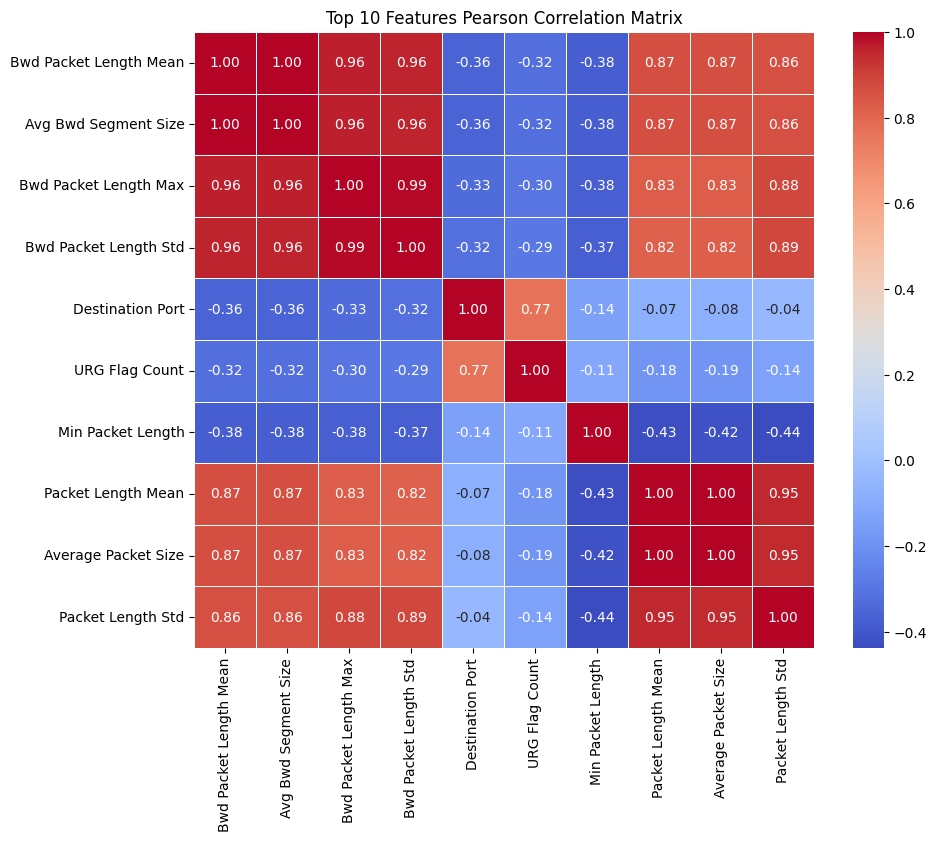

In [60]:

pearson_corr = df.corr(method='pearson')['Label'].abs().sort_values(ascending=False)


top_features = pearson_corr.drop('Label').head(10).index

# 3. Heatmap plot karein
plt.figure(figsize=(10, 8))
sns.heatmap(
    df[top_features].corr(method='pearson'),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Top 10 Features Pearson Correlation Matrix', fontsize=12)
plt.show()

In [61]:

leakage_features = [
    'Destination Port',
    'Init_Win_bytes_forward',
    'Init_Win_bytes_backward',
    'Timestamp'

]


df.drop(columns=leakage_features, inplace=True, errors='ignore')

print("Remaining Shape after fixing Data Leakage:", df.shape)
drop_more = ['Bwd Packet Length Min','URG Flag Count','min_seg_size_forward',
             'act_data_pkt_fwd','Fwd Packet Length Max','Fwd Packet Length Min']
df.drop(columns=drop_more, inplace=True, errors='ignore')

Remaining Shape after fixing Data Leakage: (218219, 66)


In [62]:

corr_features = df.drop('Label', axis=1).corr().abs()


upper = corr_features.where(np.triu(np.ones(corr_features.shape), k=1).astype(bool))


to_drop = [column for column in upper.columns if any(upper[column] > 0.90)]

print(f"Total collinear columns to drop ({len(to_drop)}):")
print(to_drop)


df.drop(columns=to_drop, inplace=True)
print("\nFinal shape after removing multicollinearity:", df.shape)

Total collinear columns to drop (34):
['Total Backward Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Std', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow IAT Std', 'Flow IAT Max', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'SYN Flag Count', 'ECE Flag Count', 'Average Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Fwd Header Length.1', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Max', 'Idle Min']

Final shape after removing multicollinearity: (218219, 26)


In [63]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

#Test and Train the data
X = df.drop('Label', axis=1)
y = df['Label']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train set shape: {X_train.shape}, Test set shape: {X_test.shape}")
print("\nTrain class distribution:\n", y_train.value_counts(normalize=True))

#RobustScalar to handle outliers
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nScaling complete! Data ready for model training.")

Train set shape: (174575, 25), Test set shape: (43644, 25)

Train class distribution:
 Label
1    0.58663
0    0.41337
Name: proportion, dtype: float64

Scaling complete! Data ready for model training.


In [64]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=10, n_jobs=-1)
knn.fit(X_train_scaled, y_train)


y_pred = knn.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     18041
           1       0.99      1.00      1.00     25603

    accuracy                           1.00     43644
   macro avg       1.00      0.99      1.00     43644
weighted avg       1.00      1.00      1.00     43644



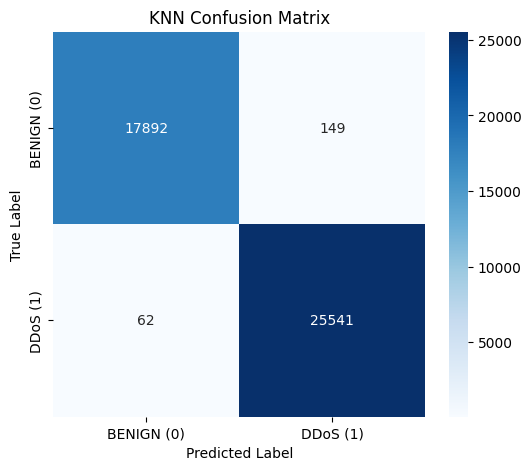

In [65]:
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['BENIGN (0)', 'DDoS (1)'],
            yticklabels=['BENIGN (0)', 'DDoS (1)'])
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()



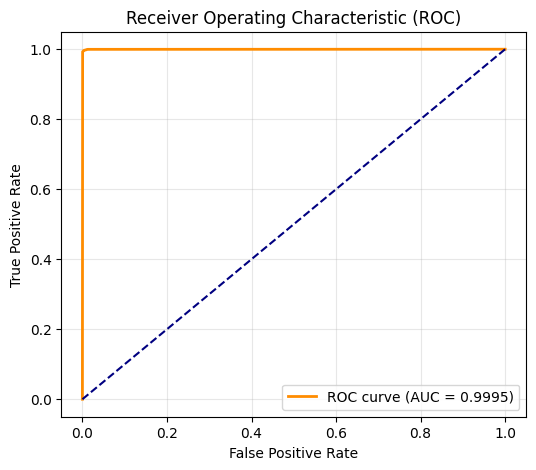

In [66]:
from sklearn.metrics import roc_curve, auc

# 5000 samples par fast probability calculation (KNN 44k par bohot slow ho jata hai)
sample_idx = np.random.RandomState(42).choice(len(X_test_scaled), size=5000, replace=False)
y_prob_sample = knn.predict_proba(X_test_scaled[sample_idx])[:, 1]
y_test_sample = y_test.iloc[sample_idx]

# ROC & AUC
fpr, tpr, _ = roc_curve(y_test_sample, y_prob_sample)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.title('Receiver Operating Characteristic (ROC)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

In [67]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
print(f"Total Errors: {cm[0, 1] + cm[1, 0]} out of {len(y_test)}")

Confusion Matrix:
[[17892   149]
 [   62 25541]]
Total Errors: 211 out of 43644


In [68]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Train
rf = RandomForestClassifier(n_estimators=100, max_depth=3,random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train)

# 2. Predict & Score
y_pred_rf = rf.predict(X_test_scaled)
print(classification_report(y_test, y_pred_rf))

# 3. Misclassifications
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(f"Total Errors: {cm_rf[0, 1] + cm_rf[1, 0]} out of {len(y_test)}")

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     18041
           1       0.99      1.00      0.99     25603

    accuracy                           0.99     43644
   macro avg       0.99      0.99      0.99     43644
weighted avg       0.99      0.99      0.99     43644

Total Errors: 269 out of 43644


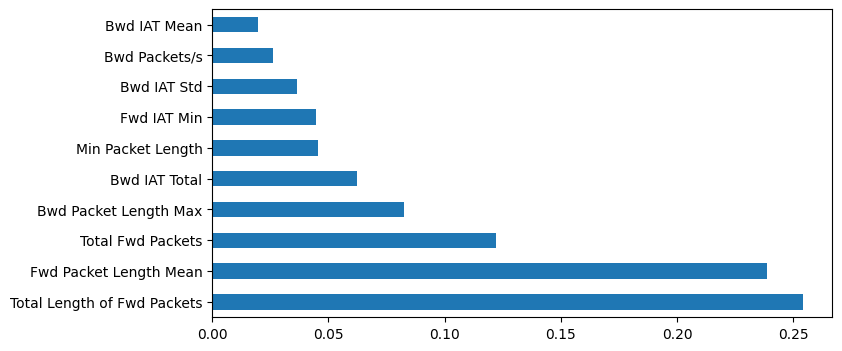

In [69]:
# Top 10 Features
feat = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
feat.head(10).plot(kind='barh', figsize=(8, 4))
plt.show()

In [70]:
train_acc = rf.score(X_train_scaled, y_train)
test_acc = rf.score(X_test_scaled, y_test)

print(f"Train Accuracy: {train_acc * 100:.3f}%")
print(f"Test Accuracy:  {test_acc * 100:.3f}%")
print(f"Accuracy Gap:   {abs(train_acc - test_acc) * 100:.3f}%")

Train Accuracy: 99.354%
Test Accuracy:  99.384%
Accuracy Gap:   0.029%


In [71]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_val_score(rf, X_train_scaled, y_train, cv=cv, scoring='f1', n_jobs=-1)

print(f"10-Fold F1-Scores: {scores}")
print(f"Mean F1: {scores.mean():.4f} (- {scores.std():.4f})")

10-Fold F1-Scores: [0.99465345 0.99407249 0.99431183 0.99445903 0.99411679 0.99435688
 0.99484436 0.99441178 0.99479901 0.99518318]
Mean F1: 0.9945 (- 0.0003)
